# Notebook 13 — Diversity Re-Ranking with MMR (MVP First)

**Inputs:** Notebook 11 `*_deepfm_deepfm_top500.parquet`, Notebook 09 `*_ranking_features_top500.parquet`, Notebook 02 eligible-positive counts. **Selection:** Validation only; Test evaluated only after lambda is frozen.

**MMR:** `lambda * normalized_relevance - (1-lambda) * max_similarity_to_selected`. Similarity uses category / parent / root. Unknown categories are not considered similar. Greedy MMR re-ranks the DeepFM **top 150** candidates to produce the first 100; the remaining 400 retain their original DeepFM relative order. All 500 candidates are preserved. This is a latency-aware MVP approximation, not full-pool MMR.

**Important:** Diversity is computed from available category metadata, not item content embeddings. Category coverage/ILD can improve even when relevance decreases. Missing category labels are reported separately.

In [1]:
from pathlib import Path
import json,time
import numpy as np,pandas as pd,duckdb,matplotlib.pyplot as plt
from IPython.display import display
SEED=42; KS=(20,50,100); LAMBDAS=(1.0,0.9,0.8,0.7,0.6); MMR_POOL=150; MMR_DEPTH=100
ROOT=next((p for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents) if (p/'data'/'processed'/'notebook02.duckdb').exists()),None)
assert ROOT is not None,'Open project root or notebooks/; missing notebook02.duckdb'
OUT=ROOT/'data'/'processed';REPORT=ROOT/'data'/'reports';PLOTS=REPORT/'notebook13_plots'
REPORT.mkdir(exist_ok=True,parents=True);PLOTS.mkdir(exist_ok=True,parents=True)
for s in ('validation','test'):
    for p in (OUT/f'{s}_deepfm_deepfm_top500.parquet',OUT/f'{s}_ranking_features_top500.parquet'):
        assert p.exists(),f'Missing input: {p}'
assert 0<MMR_DEPTH<=MMR_POOL<=500
print('Project:',ROOT,'MMR_POOL:',MMR_POOL,'MMR_DEPTH:',MMR_DEPTH)


Project: C:\YR_Python_Code\multi-stage-ads-recommendation\notebooks MMR_POOL: 150 MMR_DEPTH: 100


## 1. Load predictions and point-in-time category features

Use the category snapshot from Notebook 09, aligned strictly on `(user_id, item_id)`. Never recompute category from post-cutoff data. `model_rank` in Notebook 11 determines the original DeepFM ordering.

In [2]:
CATCOLS=['category_id','parent_category_id','root_category_id']
def load_split(split):
    p=pd.read_parquet(OUT/f'{split}_deepfm_deepfm_top500.parquet')
    required={'user_id','item_id','label','score','model_rank'}
    assert required<=set(p.columns),(split,required-set(p.columns))
    cats=pd.read_parquet(OUT/f'{split}_ranking_features_top500.parquet',columns=['user_id','item_id']+CATCOLS)
    assert not cats[['user_id','item_id']].duplicated().any()
    assert not p[['user_id','item_id']].duplicated().any()
    d=p.merge(cats,on=['user_id','item_id'],how='left',validate='one_to_one',sort=False,indicator=True)
    assert (d._merge=='both').all(),f'{split}: missing feature rows'
    d=d.drop(columns='_merge').sort_values(['user_id','model_rank','item_id'],kind='stable').reset_index(drop=True)
    sizes=d.groupby('user_id',sort=False).size();assert sizes.min()==sizes.max()==500
    assert d.groupby('user_id',sort=False).model_rank.agg(['min','max']).eq([1,500]).all().all()
    for c in CATCOLS:d[c]=pd.to_numeric(d[c],errors='coerce').fillna(-1).astype('int64')
    d['user_id']=d.user_id.astype('int64');d['item_id']=d.item_id.astype('int64')
    assert d.label.isin([0,1]).all() and np.isfinite(d.score.to_numpy()).all()
    return d
VAL=load_split('validation')
print('Validation rows:',len(VAL),'users:',VAL.user_id.nunique(),'missing category:',round((VAL.category_id<0).mean(),4))
display(VAL.head(3))


Validation rows: 1828500 users: 3657 missing category: 0.0439


,user_id,item_id,label,score,original_rank,model_rank,category_id,parent_category_id,root_category_id
0,496,348237,0,-2.119848,1,1,-1,-1,-1
1,496,232509,0,-2.213691,2,2,64,206,1532
2,496,45337,0,-2.296871,5,3,64,206,1532


## 2. Load eligible future positives (full denominator)

Recall@K counts hits divided by **all eligible future positive pairs**, not just positives already retrieved in the top 500. This preserves Notebook 10/11 evaluation semantics.

In [3]:
con=duckdb.connect(str(OUT/'notebook02.duckdb'),read_only=True)
def eligible_counts(split):
    t=con.execute(f'SELECT user_id, COUNT(*) AS n FROM {split}_positives GROUP BY user_id').df()
    return dict(zip(t.user_id.astype('int64'),t.n.astype('int64')))
POS_VAL=eligible_counts('validation')
assert set(VAL.user_id.unique())==set(POS_VAL)
print('Validation eligible positives:',sum(POS_VAL.values()),'candidate positives:',int(VAL.label.sum()))


Validation eligible positives: 9020 candidate positives: 1996


## 3. Category similarity and greedy MMR

Similarity: same known leaf category = 1; else same known parent = 0.7; else same known root = 0.4; else 0. `-1` (missing) never matches. Scores are min-max normalized **within each user and within the MMR pool**. Deterministic tie-break uses original DeepFM order. `lambda=1` exactly reproduces DeepFM ordering.

In [4]:
def similarity_to_one(cat,selected):
    # cat: (pool,3), selected: (3,), leaf > parent > root
    result=np.zeros(len(cat),dtype=np.float32)
    for col,sim in ((2,0.4),(1,0.7),(0,1.0)):
        if selected[col]>=0:
            result=np.where(cat[:,col]==selected[col],np.float32(sim),result)
    return result

def mmr_one_user(scores,cat,lam,pool=MMR_POOL,depth=MMR_DEPTH):
    n=len(scores);assert n==500
    if lam>=1.0:return np.arange(n,dtype=np.int32)
    p=min(pool,n);d=min(depth,p)
    sc=np.asarray(scores[:p],dtype=np.float64)
    span=sc.max()-sc.min()
    rel=((sc-sc.min())/span if span>1e-12 else np.ones(p)).astype(np.float32)
    # Preserve original order as deterministic tie-break (small epsilon)
    maxsim=np.zeros(p,dtype=np.float32);remaining=np.ones(p,dtype=bool)
    chosen=np.empty(d,dtype=np.int32)
    for t in range(d):
        obj=np.float32(lam)*rel-np.float32(1-lam)*maxsim
        obj[~remaining]=-np.inf
        j=int(np.argmax(obj));chosen[t]=j;remaining[j]=False
        maxsim=np.maximum(maxsim,similarity_to_one(cat[:p],cat[j]))
    # selected first; unused pool candidates and tail follow original DeepFM order
    rest=np.flatnonzero(remaining).astype(np.int32)
    return np.concatenate([chosen,rest,np.arange(p,n,dtype=np.int32)])

def make_rerank(d,lam):
    assert len(d)%500==0
    sc=d.score.to_numpy(dtype=np.float64).reshape(-1,500)
    cat=d[CATCOLS].to_numpy(dtype=np.int64).reshape(-1,500,3)
    idx=np.empty((len(sc),500),dtype=np.int32)
    t0=time.perf_counter()
    for i in range(len(sc)):
        idx[i]=mmr_one_user(sc[i],cat[i],lam)
    assert np.all(np.sort(idx,axis=1)==np.arange(500))
    print(f'lambda={lam:.2f}: {len(sc)} users in {time.perf_counter()-t0:.1f}s')
    return idx

# Lightweight synthetic correctness checks
x=np.linspace(1,0,500); c=np.full((500,3),-1,dtype=np.int64)
assert np.array_equal(mmr_one_user(x,c,1.0),np.arange(500))
assert np.array_equal(np.sort(mmr_one_user(x,c,.7)),np.arange(500))


## 4. User-group ranking + diversity metrics

Category Coverage@K: mean number of unique **known leaf categories** per user (also normalized by K). ILD@K: mean pairwise `1 - category_similarity` among recommended items. Unknown categories are counted as maximally dissimilar by design; missing-category rate is reported to expose that limitation. NDCG ideal uses all eligible positives for each user.

In [5]:
def evaluate(d,idx,pos,split,method):
    n=len(d)//500
    users=d.user_id.to_numpy().reshape(n,500)[:,0]
    eligible=np.array([pos[int(u)] for u in users],dtype=np.int64)
    assert (eligible>0).all() and len(pos)==n
    y=np.take_along_axis(d.label.to_numpy(dtype=np.int8).reshape(n,500),idx,axis=1)
    cat=np.take_along_axis(d[CATCOLS].to_numpy(dtype=np.int64).reshape(n,500,3),idx[:,:,None],axis=1)
    total=int(eligible.sum()); rows=[]
    for k in KS:
        top=y[:,:k]; hits=int(top.sum());userhits=top.sum(axis=1)
        discount=1/np.log2(np.arange(2,k+2))
        dcg=(top*discount).sum(axis=1)
        cum=np.r_[0,np.cumsum(discount)]
        ndcg=float(np.mean(dcg/cum[np.minimum(eligible,k)]))
        leaf=cat[:,:k,0]
        distinct=np.array([len(np.unique(v[v>=0])) for v in leaf],dtype=np.float32)
        ild=np.zeros(n,dtype=np.float64)
        for i in range(n):
            cc=cat[i,:k,:]
            # pairwise matrix, matching hierarchical categories; unknown never matches
            sim=np.zeros((k,k),dtype=np.float32)
            for col,w in ((2,.4),(1,.7),(0,1.)):
                a=cc[:,col]
                sim=np.where((a[:,None]>=0)&(a[:,None]==a[None,:]),np.float32(w),sim)
            tri=np.triu_indices(k,1)
            ild[i]=float((1-sim[tri]).mean())
        rows.append(dict(split=split,method=method,k=k,lambda_mmr=float(method.split('_')[-1]) if method.startswith('mmr_') else 1.0,
            hits=hits,eligible_positive_pairs=total,recall_micro=hits/total,hit_rate=float(np.mean(userhits>0)),ndcg=ndcg,
            category_coverage=float(distinct.mean()),category_coverage_per_slot=float((distinct/k).mean()),
            intra_list_diversity=float(ild.mean()),missing_category_rate=float(np.mean(leaf<0)),user_coverage=1.0))
    return rows

IDENTITY=np.broadcast_to(np.arange(500,dtype=np.int32),(len(VAL)//500,500)).copy()
base_val=evaluate(VAL,IDENTITY,POS_VAL,'validation','deepfm')
print('DeepFM Validation baseline:');display(pd.DataFrame(base_val))
# Notebook 11 reproducibility audit
rpt=REPORT/'notebook11_deepfm_report.json'
if rpt.exists():
    old=json.loads(rpt.read_text(encoding='utf-8'))
    for row in base_val:
        matches=[x for x in old['ranking_metrics'] if x['split']=='validation' and x['method']=='deepfm' and x['k']==row['k']]
        assert len(matches)==1 and int(matches[0]['hits'])==row['hits'],('Notebook11 baseline mismatch',row['k'])
    print('Notebook 11 validation hits reproducibility: PASS')


DeepFM Validation baseline:


,split,method,k,lambda_mmr,hits,eligible_positive_pairs,recall_micro,hit_rate,ndcg,category_coverage,category_coverage_per_slot,intra_list_diversity,missing_category_rate,user_coverage
0,validation,deepfm,20,1.0,702,9020,0.077827,0.145201,0.054324,3.625649,0.181282,0.259304,0.042863,1.0
1,validation,deepfm,50,1.0,1027,9020,0.113858,0.192781,0.063877,9.116488,0.182330,0.320049,0.034471,1.0
2,validation,deepfm,100,1.0,1307,9020,0.144900,0.229696,0.070318,18.852884,0.188529,0.383897,0.035893,1.0


Notebook 11 validation hits reproducibility: PASS


## 5. Validation-only lambda selection

Select lambda maximizing Validation **NDCG@20**, subject to ILD@20 improving by at least `MIN_ILD_GAIN=0.02` relative to DeepFM and Recall@20 decreasing by no more than `MAX_RECALL_DROP=0.003` (absolute). If no nontrivial lambda passes, select 1.0 (no re-ranking). This explicit guardrail avoids selecting a lambda that sacrifices too much relevance for diversity. Test is not loaded until selection is frozen.

In [6]:
MIN_ILD_GAIN=0.02;MAX_RECALL_DROP=0.003
VAL_ROWS=list(base_val);VAL_IDX={1.0:IDENTITY}
for lam in LAMBDAS:
    if lam==1.0:continue
    idx=make_rerank(VAL,lam);VAL_IDX[lam]=idx
    VAL_ROWS.extend(evaluate(VAL,idx,POS_VAL,'validation',f'mmr_{lam:.2f}'))
val_df=pd.DataFrame(VAL_ROWS)
val_df.to_csv(REPORT/'notebook13_validation_lambda_sweep.csv',index=False)
view=val_df[val_df.k==20].sort_values('lambda_mmr',ascending=False)
display(view[['method','recall_micro','ndcg','hit_rate','category_coverage','intra_list_diversity','missing_category_rate']])
base=base_val[0]
eligible=view[(view.method!='deepfm') & (view.intra_list_diversity>=base['intra_list_diversity']+MIN_ILD_GAIN) & (view.recall_micro>=base['recall_micro']-MAX_RECALL_DROP)]
if len(eligible):
    selected=eligible.sort_values(['ndcg','lambda_mmr'],ascending=[False,False]).iloc[0]
    BEST_LAMBDA=float(selected.lambda_mmr)
else:BEST_LAMBDA=1.0
print('Frozen BEST_LAMBDA:',BEST_LAMBDA,'eligible candidates:',len(eligible))


lambda=0.90: 3657 users in 4.5s
lambda=0.80: 3657 users in 4.5s
lambda=0.70: 3657 users in 4.3s
lambda=0.60: 3657 users in 4.4s


,method,recall_micro,ndcg,hit_rate,category_coverage,intra_list_diversity,missing_category_rate
0,deepfm,0.077827,0.054324,0.145201,3.625649,0.259304,0.042863
3,mmr_0.90,0.077162,0.053906,0.145201,4.348647,0.308291,0.054102
6,mmr_0.80,0.074501,0.052593,0.140552,5.450916,0.386915,0.069046
9,mmr_0.70,0.068404,0.049072,0.130708,6.956795,0.513033,0.105592
12,mmr_0.60,0.057539,0.041718,0.115395,8.662565,0.702212,0.199631


Frozen BEST_LAMBDA: 0.9 eligible candidates: 1


## 6. Test once after freezing lambda

Test is loaded only in this section. No hyperparameters, diversity thresholds, or weights are changed based on Test.

In [7]:
TEST=load_split('test');POS_TEST=eligible_counts('test')
assert set(TEST.user_id.unique())==set(POS_TEST)
TEST_ID=np.broadcast_to(np.arange(500,dtype=np.int32),(len(TEST)//500,500)).copy()
TEST_MMR=make_rerank(TEST,BEST_LAMBDA)
TEST_ROWS=evaluate(TEST,TEST_ID,POS_TEST,'test','deepfm')+evaluate(TEST,TEST_MMR,POS_TEST,'test',f'mmr_{BEST_LAMBDA:.2f}')
test_df=pd.DataFrame(TEST_ROWS)
display(test_df[['method','k','recall_micro','ndcg','hit_rate','category_coverage','intra_list_diversity']])


lambda=0.90: 3572 users in 4.4s


,method,k,recall_micro,ndcg,hit_rate,category_coverage,intra_list_diversity
0,deepfm,20,0.074872,0.055948,0.134658,4.149496,0.268439
1,deepfm,50,0.109691,0.065247,0.182251,10.166014,0.325961
2,deepfm,100,0.145240,0.072722,0.228723,20.793673,0.389965
3,mmr_0.90,20,0.074142,0.055652,0.132979,4.781355,0.311540
4,mmr_0.90,50,0.108960,0.064919,0.181971,11.915174,0.368384
5,mmr_0.90,100,0.144144,0.072412,0.227884,23.640257,0.429640


## 7. Export prediction Parquet (all 500 candidates per user)

`mmr_rank` is the final display order; `score` remains the original DeepFM score and **must not** be re-sorted for serving. No synthetic MMR score is claimed. The top 100 is greedily re-ranked; remaining candidates retain their original DeepFM order.

In [8]:
def export_split(d,idx,split):
    n=len(d)//500;flat=(np.arange(n)[:,None]*500+idx).reshape(-1)
    cols=['user_id','item_id','label','score','model_rank']+CATCOLS
    p=d.iloc[flat][cols].copy().reset_index(drop=True)
    p=p.rename(columns={'model_rank':'deepfm_rank','score':'deepfm_score'})
    p['mmr_rank']=np.tile(np.arange(1,501,dtype=np.int16),n)
    p['mmr_lambda']=BEST_LAMBDA
    assert len(p)==len(d) and not p[['user_id','item_id']].duplicated().any()
    assert p.groupby('user_id',sort=False).mmr_rank.agg(['min','max']).eq([1,500]).all().all()
    dest=OUT/f'{split}_mmr_top500.parquet';p.to_parquet(dest,index=False,compression='zstd')
    return dict(split=split,path=dest.name,rows=len(p),size_mb=round(dest.stat().st_size/1048576,2))
EXPORTS=[export_split(VAL,VAL_IDX[BEST_LAMBDA],'validation'),export_split(TEST,TEST_MMR,'test')]
display(pd.DataFrame(EXPORTS))


,split,path,rows,size_mb
0,validation,validation_mmr_top500.parquet,1828500,14.55
1,test,test_mmr_top500.parquet,1786000,14.05


## 8. Plots, CSV/JSON report, and audit

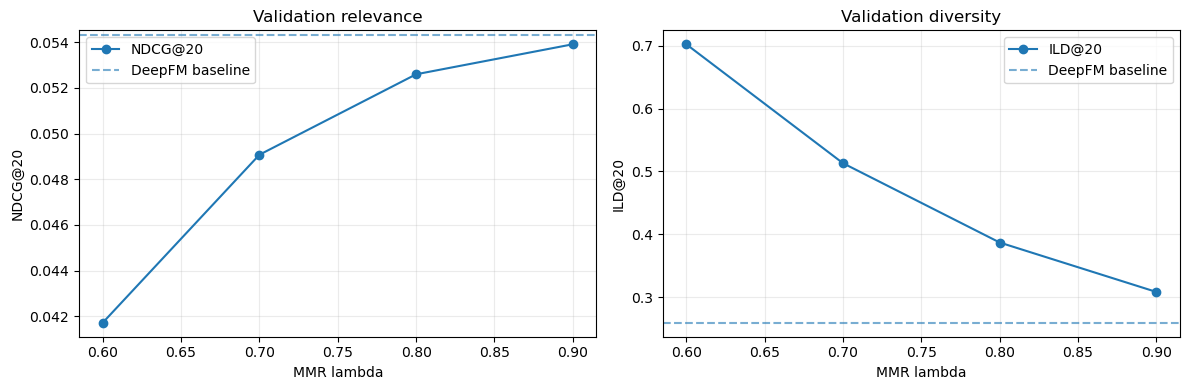

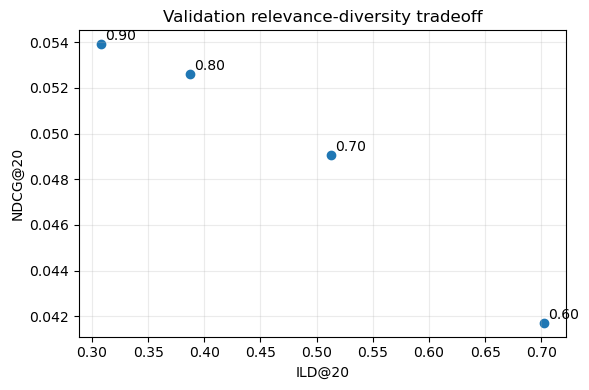

Saved: C:\YR_Python_Code\multi-stage-ads-recommendation\notebooks\data\reports\notebook13_mmr_report.json
Selected lambda: 0.9


In [9]:
all_metrics=pd.concat([val_df,test_df],ignore_index=True)
all_metrics.to_csv(REPORT/'notebook13_ranking_diversity_metrics.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(12,4))
v20=val_df[(val_df.k==20)&(val_df.method!='deepfm')].sort_values('lambda_mmr')
axes[0].plot(v20.lambda_mmr,v20.ndcg,marker='o',label='NDCG@20')
axes[0].axhline(base['ndcg'],linestyle='--',alpha=.6,label='DeepFM baseline')
axes[0].set(xlabel='MMR lambda',ylabel='NDCG@20',title='Validation relevance');axes[0].legend();axes[0].grid(alpha=.25)
axes[1].plot(v20.lambda_mmr,v20.intra_list_diversity,marker='o',label='ILD@20')
axes[1].axhline(base['intra_list_diversity'],linestyle='--',alpha=.6,label='DeepFM baseline')
axes[1].set(xlabel='MMR lambda',ylabel='ILD@20',title='Validation diversity');axes[1].legend();axes[1].grid(alpha=.25)
fig.tight_layout();fig.savefig(PLOTS/'notebook13_lambda_tradeoff.png',dpi=160);plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(6,4))
ax.scatter(v20.intra_list_diversity,v20.ndcg)
for r in v20.itertuples():ax.annotate(f'{r.lambda_mmr:.2f}',(r.intra_list_diversity,r.ndcg),xytext=(3,3),textcoords='offset points')
ax.set(xlabel='ILD@20',ylabel='NDCG@20',title='Validation relevance-diversity tradeoff');ax.grid(alpha=.25)
fig.tight_layout();fig.savefig(PLOTS/'notebook13_pareto_tradeoff.png',dpi=160);plt.show();plt.close(fig)
report={'notebook':'13_diversity_reranking_mmr','seed':SEED,
 'mmr':{'pool':MMR_POOL,'depth':MMR_DEPTH,'lambdas_tested':list(LAMBDAS),'selected_lambda':BEST_LAMBDA,
        'similarity':{'same_leaf':1.0,'same_parent':0.7,'same_root':0.4,'otherwise':0.0},
        'selection_metric':'validation NDCG@20 subject to ILD@20 and Recall@20 guardrails',
        'min_ild_gain_absolute':MIN_ILD_GAIN,'max_recall_drop_absolute':MAX_RECALL_DROP,
        'test_used_for_selection':False},
 'validation_metrics':val_df.to_dict('records'),'test_metrics':test_df.to_dict('records'),
 'prediction_exports':EXPORTS,
 'plots':['notebook13_lambda_tradeoff.png','notebook13_pareto_tradeoff.png'],
 'limitations':['Category hierarchy is a coarse proxy for semantic item similarity',
 'Unknown category pairs count as dissimilar; inspect missing_category_rate',
 'MMR greedily reorders top 100 from the DeepFM top 150; remaining items keep original order',
 'Ranking cannot recover eligible positives absent from the Top-500 candidate pool',
 'No impressions, causal CTR/CVR, online latency benchmark or production claim',
 'Category features are inherited from Notebook 09 split-level PIT snapshots']}
path=REPORT/'notebook13_mmr_report.json'
path.write_text(json.dumps(report,indent=2,ensure_ascii=False,allow_nan=False),encoding='utf-8')
print('Saved:',path)
print('Selected lambda:',BEST_LAMBDA)


## 9. MVP completion checklist

- [ ] Notebook 11 DeepFM Validation baseline reproduced
- [ ] Category features joined with no missing candidate keys
- [ ] Validation-only lambda selection with relevance/diversity guardrails
- [ ] Test evaluated after freezing lambda
- [ ] All 500 candidates preserved with deterministic MMR order
- [ ] CSV, JSON, Parquet, PNG exported

**Next:** Upload `data/reports/notebook13_mmr_report.json` for analysis. Notebook 14 can implement offline replay and latency profiling.